# Load initial

In [1]:
1.7*365

620.5

In [140]:
import pandas as pd
import numpy as np
import os
import seaborn as sns
GTE_DIR=os.environ["GTE_DIR"]
from glaciation_time_estimator.auxiliary_func.config_reader import read_config
from glaciation_time_estimator.auxiliary_func.Helper_fun import float_range
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
import matplotlib as mpl
import matplotlib.gridspec as gridspec
import cmcrameri.cm
from glaciation_time_estimator.auxiliary_func.chunking_data import ChunkLoader
import datetime as dt

In [58]:
config = read_config("/wolke_scratch/dnikolo/Glaciation_time_estimator/configs/config_n2o.yaml")
colormap = cmcrameri.cm.lipariS

/wolke_scratch/dnikolo/conda_envs/msgi_env/lib/python3.11/site-packages/xarray/backends/plugins.py:159: RuntimeWarning: 'netcdf4' fails while guessing
  warnings.warn(f"{engine!r} fails while guessing", RuntimeWarning)
/wolke_scratch/dnikolo/conda_envs/msgi_env/lib/python3.11/site-packages/xarray/backends/plugins.py:159: RuntimeWarning: 'h5netcdf' fails while guessing
  warnings.warn(f"{engine!r} fails while guessing", RuntimeWarning)
/wolke_scratch/dnikolo/conda_envs/msgi_env/lib/python3.11/site-packages/xarray/backends/plugins.py:159: RuntimeWarning: 'scipy' fails while guessing
  warnings.warn(f"{engine!r} fails while guessing", RuntimeWarning)
/wolke_scratch/dnikolo/conda_envs/msgi_env/lib/python3.11/site-packages/xarray/backends/plugins.py:168: RuntimeWarning: 'netcdf4' fails while guessing
  warnings.warn(f"{engine!r} fails while guessing", RuntimeWarning)
/wolke_scratch/dnikolo/conda_envs/msgi_env/lib/python3.11/site-packages/xarray/backends/plugins.py:168: RuntimeWarning: 'h5ne

ValueError: did not find a match in any of xarray's currently installed IO backends ['netcdf4', 'h5netcdf', 'scipy', 'cfgrib', 'gini', 'rasterio', 'zarr']. Consider explicitly selecting one of the installed engines via the ``engine`` parameter, or installing additional IO dependencies, see:
https://docs.xarray.dev/en/stable/getting-started-guide/installing.html
https://docs.xarray.dev/en/stable/user-guide/io.html

In [59]:
glac_threshold=0.4
def calculate_pole_temp_occurance_rate(dfs):
    cloud_chunk , _ , _ = dfs
    return pd.pivot_table(cloud_chunk,values='is_glaciating' ,index=["Hemisphere"], columns=["min_temp"], aggfunc='mean')
def calculate_pole_temp_occurance_rate_glac_possible(dfs):
    cloud_chunk , _ , _ = dfs
    return pd.pivot_table(cloud_chunk[cloud_chunk.max_water_frac > glac_threshold],values='is_glaciating' ,index=["Hemisphere"], columns=["min_temp"], aggfunc='mean')


# 1 Load data

CLAAS data (1 degree)

In [98]:
glac_low_res_01 = pd.read_parquet("/wolke_scratch/dnikolo/dump/regrided_data/Results/Agg_20_Glaciations_20080901.0000_20080914.2345.parquet")
glac_low_res_02 = pd.read_parquet("/wolke_scratch/dnikolo/dump/regrided_data/Results/Agg_20_Glaciations_20080915.0000_20080930.2345.parquet")
glac_low_res = pd.concat([glac_low_res_01,glac_low_res_02],axis=0,ignore_index=True)
clouds_low_res_01 = pd.read_parquet("/wolke_scratch/dnikolo/dump/regrided_data/Results/Agg_20_clouds_20080901.0000_20080914.2345.parquet")
clouds_low_res_02 = pd.read_parquet("/wolke_scratch/dnikolo/dump/regrided_data/Results/Agg_20_clouds_20080915.0000_20080930.2345.parquet")
clouds_low_res = pd.concat([clouds_low_res_01,clouds_low_res_02],axis=0,ignore_index=True)


CLAAS data (original - 0.15)

In [61]:
loader = ChunkLoader([2008],config,filter=True)

Cloud_fps: {2008: '/wolke_scratch/dnikolo/Final_results/2008_all.parquet'}


Model 160 km

In [99]:
clouds_model = pd.read_parquet("/wolke_scratch/dnikolo/ICON_Data/Online_postproc_out_4_ctt/Results/Agg_03_clouds_20080901.0015_20080907.2345.parquet")
glac_model = pd.read_parquet("/wolke_scratch/dnikolo/ICON_Data/Online_postproc_out_4_ctt/Results/Agg_03_glaciations_20080901.0015_20080907.2345.parquet")

In [100]:
start_time=pd.Timestamp("2008-09-01")
end_time= pd.Timestamp("2008-09-08")
def time_filter(df):
    return df[(df.track_start_time>=start_time) & (df.track_start_time<end_time)]
def get_peak_if(glac_df_row):
    return glac_df_row["ice_frac_hist"][glac_df_row["Glac_peak_ind"]]
def set_peak_if(glac_df):
    glac_df["Peak IF"] = glac_df.apply(get_peak_if,axis=1)
def filter_df(df):
    return df[(~df.is_large_pix_cloud) & (abs(df.avg_lat)>30)]
def preproc_glac(glac_df):
    set_peak_if(glac_df)
    return filter_df(time_filter(glac_df))
def preproc_cloud(cloud_df):
    return filter_df(time_filter(cloud_df))

glac_high_res = preproc_glac(loader.glac_chunk)
clouds_high_res = preproc_cloud(loader.cloud_chunk)
glac_low_res = preproc_glac(glac_low_res)
clouds_low_res = preproc_cloud(clouds_low_res)
glac_model=preproc_glac(glac_model)
clouds_model=preproc_cloud(clouds_model)
# set_peak_if(glac_model)
# set_peak_if(glac_high_res)
# set_peak_if(glac_low_res)
# glac_high_res = time_filter(loader.glac_chunk)
# clouds_low_res=time_filter(clouds_low_res)
# glac_low_res=time_filter(glac_low_res)

# clouds_high_res = clouds_high_res[clouds_high_res["avg_size[km]"]>3e4]

In [101]:
len(glac_model)

6029

In [102]:
len(glac_high_res)

1405

In [103]:
len(glac_low_res)

1481

In [104]:
def set_is_glaciating(cloud_df,glac_df):
    cloud_df['is_glaciating'] = (
                    cloud_df.index.isin(
                        glac_df['Cloud_ID']
                    )
                )

set_is_glaciating(clouds_low_res,glac_low_res)
# set_is_glaciating(clouds_model_offline,glac_model_offline)
set_is_glaciating(clouds_model,glac_model)


In [105]:
def set_hemisphere(cloud_df):
    cloud_df['Hemisphere'] = np.where(cloud_df['avg_lat']>=0,'North','South')
# set_hemisphere(clouds_model_offline)
set_hemisphere(clouds_model)

In [106]:
glac_model.keys()

Index(['Cloud_ID', 'Time [m]', 'Magnitude', 'Glac_start_ind', 'Glac_peak_ind',
       'Linear', 'line_rmse', 'Rate_arr', 'Mean_glac_rate',
       'Glaciation time [h]', 'tracknumber', 'is_large_pix_cloud',
       'is_cot_valid_cloud', 'is_ctp_valid_cloud', 'is_liq', 'is_mix',
       'is_ice', 'max_water_frac', 'max_ice_fraction', 'avg_size[km]',
       'max_size[km]', 'min_size[km]', 'avg_size[px]', 'max_size[px]',
       'min_size[px]', 'track_start_time', 'track_length', 'avg_cot',
       'avg_ctp', 'avg_ctt', 'glaciation_start_time', 'glaciation_end_time',
       'avg_lat', 'avg_lon', 'start_ice_fraction', 'end_ice_fraction',
       'ice_frac_hist', 'cot_hist', 'cot_std_hist', 'cot_nan_frac_hist',
       'ctp_hist', 'ctp_std_hist', 'ctp_nan_frac_hist', 'ctt_hist',
       'ctt_std_hist', 'lat_hist', 'lon_hist', 'size_hist_km', 'min_temp',
       'max_temp', 'pole', 'Hemisphere', 'Lifetime [h]', 'Peak IF'],
      dtype='object')

In [107]:
clouds_model.keys()

Index(['tracknumber', 'is_large_pix_cloud', 'is_cot_valid_cloud',
       'is_ctp_valid_cloud', 'is_liq', 'is_mix', 'is_ice', 'max_water_frac',
       'max_ice_fraction', 'avg_size[km]', 'max_size[km]', 'min_size[km]',
       'avg_size[px]', 'max_size[px]', 'min_size[px]', 'track_start_time',
       'track_length', 'avg_cot', 'avg_ctp', 'avg_ctt',
       'glaciation_start_time', 'glaciation_end_time', 'avg_lat', 'avg_lon',
       'start_ice_fraction', 'end_ice_fraction', 'ice_frac_hist', 'cot_hist',
       'cot_std_hist', 'cot_nan_frac_hist', 'ctp_hist', 'ctp_std_hist',
       'ctp_nan_frac_hist', 'ctt_hist', 'ctt_std_hist', 'lat_hist', 'lon_hist',
       'size_hist_km', 'min_temp', 'max_temp', 'pole', 'Hemisphere',
       'Lifetime [h]', 'is_glaciating'],
      dtype='object')

In [108]:
clouds_model.is_large_pix_cloud.value_counts()

is_large_pix_cloud
False    25996
Name: count, dtype: int64

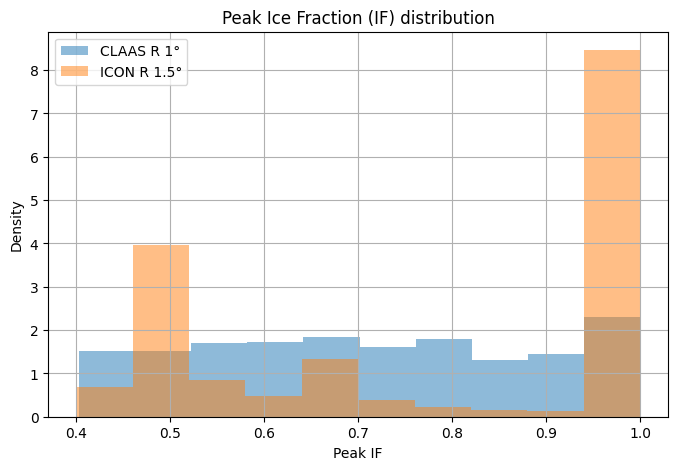

In [109]:
fig, ax = plt.subplots(figsize=(8, 5))
glac_low_res["Peak IF"].hist( alpha=0.5, density=True,label="CLAAS R 1°")
# glac_model_offline["Time [m]"].hist(bins=np.arange(7.5,181,15), alpha=0.5, density=True,label="ICON Old WBF R 1.5°")
glac_model["Peak IF"].hist( alpha=0.5, density=True,label="ICON R 1.5°")
plt.title("Peak Ice Fraction (IF) distribution")
plt.xlabel("Peak IF")
plt.ylabel("Density")
plt.legend()

In [138]:
clouds_low_res["avg_size[km]"]

0         214.957317
1          31.636364
2          26.178571
3          19.680000
4          14.147059
             ...    
117976      2.600000
117977      2.400000
117978      1.600000
117979      1.250000
117981      2.200000
Name: avg_size[km], Length: 55940, dtype: float64

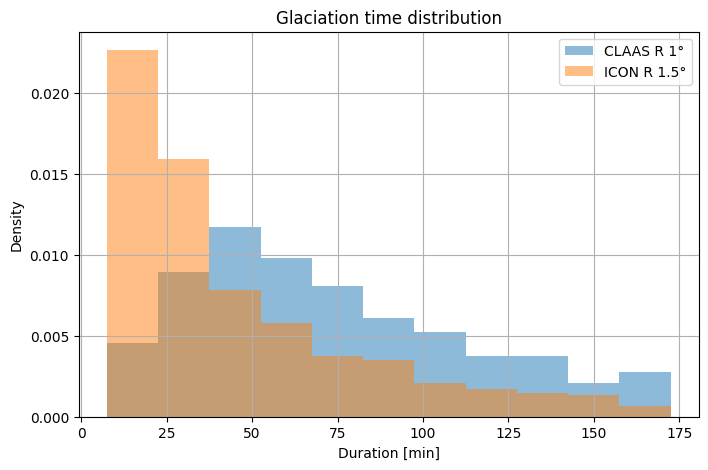

In [137]:
fig, ax = plt.subplots(figsize=(8, 5))
glac_low_res["Time [m]"].hist(bins=np.arange(7.5,181,15), alpha=0.5, density=True,label="CLAAS R 1°")
# glac_model_offline["Time [m]"].hist(bins=np.arange(7.5,181,15), alpha=0.5, density=True,label="ICON Old WBF R 1.5°")
glac_model["Time [m]"].hist(bins=np.arange(7.5,181,15), alpha=0.5, density=True,label="ICON R 1.5°")
# glac_model["Time [m]"].hist( alpha=0.5, density=True,label="ICON R 1.5°")
plt.title("Glaciation time distribution")
plt.xlabel("Duration [min]")
plt.ylabel("Density")
plt.legend()

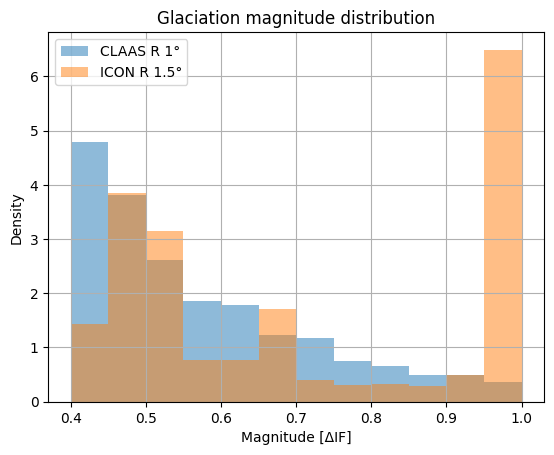

In [111]:

(glac_low_res["Magnitude"]).hist( alpha=0.5, density=True,label="CLAAS R 1°",range=(0.4,1),bins=12)
# (glac_high_res["Magnitude"]).hist( alpha=0.5, density=True,label="CLAAS R 0.05°")
# (glac_model_offline["Magnitude"]).hist( alpha=0.5, density=True,label="ICON Old WBF R 1.5°")
(glac_model["Magnitude"]).hist( alpha=0.5, density=True,label="ICON R 1.5°",range=(0.4,1),bins=12)
plt.title("Glaciation magnitude distribution")
plt.xlabel("Magnitude [ΔIF]")
plt.ylabel("Density")
plt.legend()

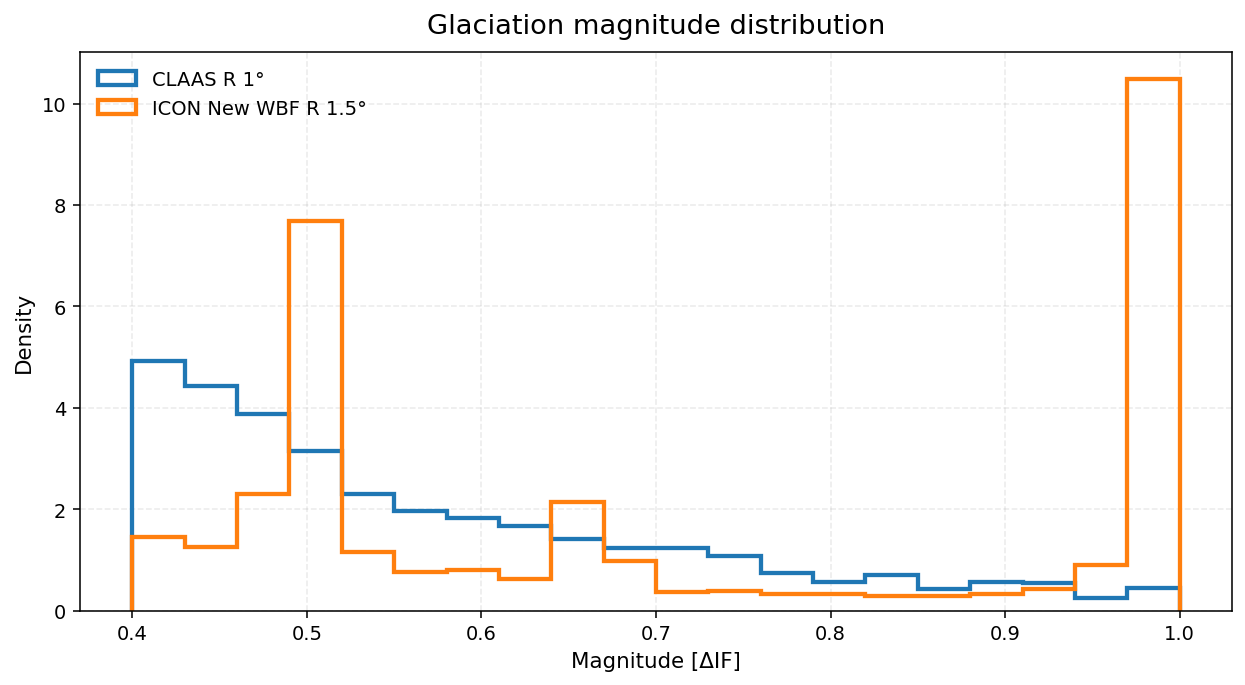

In [112]:
import numpy as np
import matplotlib.pyplot as plt

# Optional: cleaner style
plt.style.use("default")  # or "seaborn-v0_8-whitegrid" if available

fig, ax = plt.subplots(figsize=(9, 5), dpi=140)

# Use common bins so curves are directly comparable
all_vals = np.concatenate([
    glac_low_res["Magnitude"].dropna().values,
    # glac_model_offline["Magnitude"].dropna().values,
    glac_model["Magnitude"].dropna().values
])
bins = np.histogram_bin_edges(all_vals, bins=20)

ax.hist(
    glac_low_res["Magnitude"].dropna(),
    bins=bins, density=True, histtype="step", linewidth=2.2,
    label="CLAAS R 1°"
)

# ax.hist(
#     glac_high_res["Magnitude"].dropna(),
#     bins=bins, density=True, histtype="step", linewidth=2.2,
#     label="CLAAS R 0.05°"
# )

# ax.hist(
#     glac_model_offline["Magnitude"].dropna(),
#     bins=bins, density=True, histtype="step", linewidth=2.2,
#     label="ICON Old WBF R 1.5°"
# )

ax.hist(
    glac_model["Magnitude"].dropna(),
    bins=bins, density=True, histtype="step", linewidth=2.2,
    label="ICON New WBF R 1.5°"
)

ax.set_title("Glaciation magnitude distribution", fontsize=14, pad=10)
ax.set_xlabel("Magnitude [ΔIF]", fontsize=11)
ax.set_ylabel("Density", fontsize=11)
ax.grid(True, alpha=0.25, linestyle="--")
ax.legend(frameon=False)
plt.tight_layout()
plt.show()


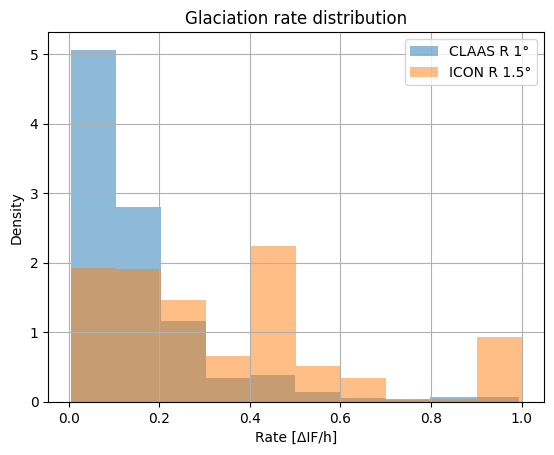

In [113]:
(glac_low_res["Magnitude"]/(glac_low_res["Time [m]"]/15)).hist( alpha=0.5, density=True,label="CLAAS R 1°")
# glac_model_offline["Time [m]"].hist(bins=np.arange(7.5,181,15), alpha=0.5, density=True,label="ICON R 1.5°")
# (glac_model_offline["Magnitude"]/(glac_model_offline["Time [m]"]/15)).hist( alpha=0.5, density=True,label="ICON Old WBF R 1.5°")
(glac_model["Magnitude"]/(glac_model["Time [m]"]/15)).hist( alpha=0.5, density=True,label="ICON R 1.5°")

plt.title("Glaciation rate distribution")
plt.xlabel("Rate [ΔIF/h]")
plt.ylabel("Density")
plt.legend()


In [114]:
from scipy.signal import savgol_filter

def noise_filter_4(row, w=4, order=2):
    IF_hist = np.array(row['ice_frac_hist'])
    return savgol_filter(IF_hist, w, order)

In [115]:
len(glac_low_res)

1481

In [116]:
se_sum=0
sample_count=0
for i, row in glac_low_res.iterrows():
    data = np.array(row['ice_frac_hist'])
    filt_data = noise_filter_4(row)
    # filt_data = savgol_filter(data, window_length=5, polyorder=2)
    first_estimate=0.1
    meas_idx = (data<1-first_estimate) & (data>first_estimate)
    se_sum += (np.square(data[meas_idx] - filt_data[meas_idx])).sum()
    sample_count+=len(data[meas_idx])
print(np.sqrt(se_sum/sample_count))

0.059820426955276944


In [117]:
se_sum=0
sample_count=0
for i, row in glac_model.iterrows():
    data = np.array(row['ice_frac_hist'])
    filt_data = noise_filter_4(row)
    # filt_data = savgol_filter(data, window_length=5, polyorder=2)
    first_estimate=0.1
    meas_idx = (data<1-first_estimate) & (data>first_estimate)
    se_sum += (np.square(data[meas_idx] - filt_data[meas_idx])).sum()
    sample_count+=len(data[meas_idx])
print(np.sqrt(se_sum/sample_count))

0.10986116265408251


In [118]:
se_sum=0
sample_count=0
for i, row in glac_model.iterrows():
    data = np.array(row['ice_frac_hist'])
    filt_data = noise_filter_4(row)
    # filt_data = savgol_filter(data, window_length=5, polyorder=2)
    first_estimate=0.1
    meas_idx = (data<1-first_estimate) & (data>first_estimate)
    se_sum += (np.square(data[meas_idx] - filt_data[meas_idx])).sum()
    sample_count+=len(data[meas_idx])
print(np.sqrt(se_sum/sample_count))

0.10986116265408251


In [119]:
(glac_low_res["Time [m]"]==15).value_counts()

Time [m]
False    1396
True       85
Name: count, dtype: int64

In [120]:
print(glac_low_res.track_length.median())
print(glac_low_res["Time [m]"].median())
print(glac_low_res["Time [m]"].std())

0 days 02:45:00
75.0
136.89564421206944


In [121]:
print(glac_high_res.track_length.median())
print(glac_high_res["Time [m]"].median())

0 days 01:45:00
60.0


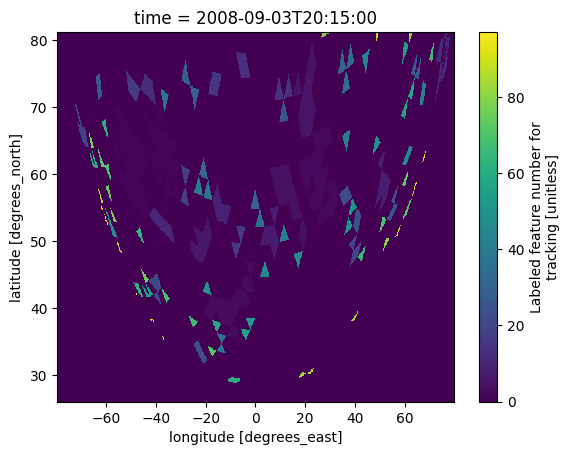

In [122]:
import xarray as xr
tracked_data = xr.open_dataset("/wolke_scratch/dnikolo/ICON_Data/Job_output_online/sp/Agg_03_T_12_06/20080901.0015_20080907.2345/pixel_path_tracking/20080901.0015_20080907.2345/cloudtracks_20080903_201500.nc")
tracked_data.isel(time=0).feature_number.plot()

In [123]:
print(len(clouds_low_res),len(clouds_high_res),len(clouds_model))

55940 51088 25996


In [124]:
clouds_low_res.is_glaciating.value_counts()

is_glaciating
False    54478
True      1462
Name: count, dtype: int64

/tmp/ipykernel_37801/2979485980.py:20: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_yticklabels(['{:,.0%}'.format(x) for x in vals])


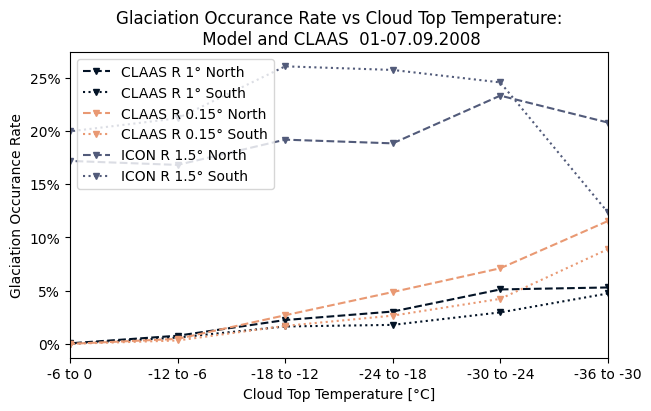

In [132]:
fig,ax = plt.subplots(1, 1, figsize=(6.4,  4), layout="constrained")
high_res_occ_rate = calculate_pole_temp_occurance_rate((clouds_high_res,None,None))
low_res_occ_rate = calculate_pole_temp_occurance_rate((clouds_low_res,None,None))
# model_occ_rate = calculate_pole_temp_occurance_rate((clouds_model_offline,None,None))
model_online_occ_rate = calculate_pole_temp_occurance_rate((clouds_model,None,None))

ax.plot(low_res_occ_rate.columns,low_res_occ_rate.loc['North'],label='CLAAS R 1° North',color=colormap(0),linestyle='dashed',marker='v',markersize=4)
ax.plot(low_res_occ_rate.columns,low_res_occ_rate.loc['South'],label='CLAAS R 1° South',color=colormap(0),linestyle='dotted',marker='v',markersize=4)
ax.plot(high_res_occ_rate.columns,high_res_occ_rate.loc['North'],label='CLAAS R 0.15° North',color = colormap(3),linestyle='dashed',marker='v',markersize=4)
ax.plot(high_res_occ_rate.columns,high_res_occ_rate.loc['South'],label='CLAAS R 0.15° South',color = colormap(3),linestyle='dotted',marker='v',markersize=4)
# ax.plot(model_occ_rate.columns,model_occ_rate.loc['North'],label='ICON Old WBF R 1.5° North',color=colormap(2),linestyle='dashed',marker='v',markersize=4)
# ax.plot(model_occ_rate.columns,model_occ_rate.loc['South'],label='ICON Old WBF R 1.5° South',color=colormap(2),linestyle='dotted',marker='v',markersize=4)
ax.plot(model_online_occ_rate.columns,model_online_occ_rate.loc['North'],label='ICON R 1.5° North',color=colormap(4),linestyle='dashed',marker='v',markersize=4)
ax.plot(model_online_occ_rate.columns,model_online_occ_rate.loc['South'],label='ICON R 1.5° South',color=colormap(4),linestyle='dotted',marker='v',markersize=4)

ax.set_xlim(-36,-6)

ax.invert_xaxis()
vals = ax.get_yticks()
ax.set_yticklabels(['{:,.0%}'.format(x) for x in vals])
ax.set_ylabel('Glaciation Occurance Rate')
ax.legend(loc="upper left")
ax.set_xlabel('Cloud Top Temperature [°C]')
ax.set_xticks(np.arange(-36,-6+1,6),labels=[f"{i} to {i+6}" for i in range(-36,0,6)])
ax.set_title('Glaciation Occurance Rate vs Cloud Top Temperature:\n Model and CLAAS  01-07.09.2008')
fig.savefig("/wolke_scratch/dnikolo/MSGI/figures/model_vs_CLAAS_occ_rate.png",dpi=300)

/tmp/ipykernel_37801/3803566814.py:20: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_yticklabels(['{:,.0%}'.format(x) for x in vals])


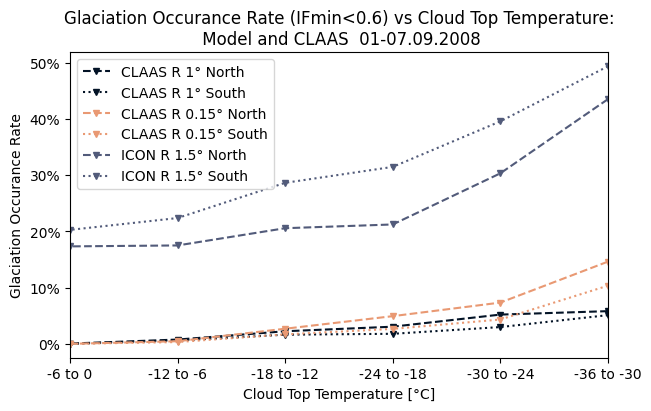

In [135]:
fig,ax = plt.subplots(1, 1, figsize=(6.4,  4), layout="constrained")
high_res_occ_rate = calculate_pole_temp_occurance_rate_glac_possible((clouds_high_res,None,None))
low_res_occ_rate = calculate_pole_temp_occurance_rate_glac_possible((clouds_low_res,None,None))
# model_occ_rate = calculate_pole_temp_occurance_rate((clouds_model_offline,None,None))
model_online_occ_rate = calculate_pole_temp_occurance_rate_glac_possible((clouds_model,None,None))

ax.plot(low_res_occ_rate.columns,low_res_occ_rate.loc['North'],label='CLAAS R 1° North',color=colormap(0),linestyle='dashed',marker='v',markersize=4)
ax.plot(low_res_occ_rate.columns,low_res_occ_rate.loc['South'],label='CLAAS R 1° South',color=colormap(0),linestyle='dotted',marker='v',markersize=4)
ax.plot(high_res_occ_rate.columns,high_res_occ_rate.loc['North'],label='CLAAS R 0.15° North',color = colormap(3),linestyle='dashed',marker='v',markersize=4)
ax.plot(high_res_occ_rate.columns,high_res_occ_rate.loc['South'],label='CLAAS R 0.15° South',color = colormap(3),linestyle='dotted',marker='v',markersize=4)
# ax.plot(model_occ_rate.columns,model_occ_rate.loc['North'],label='ICON Old WBF R 1.5° North',color=colormap(2),linestyle='dashed',marker='v',markersize=4)
# ax.plot(model_occ_rate.columns,model_occ_rate.loc['South'],label='ICON Old WBF R 1.5° South',color=colormap(2),linestyle='dotted',marker='v',markersize=4)
ax.plot(model_online_occ_rate.columns,model_online_occ_rate.loc['North'],label='ICON R 1.5° North',color=colormap(4),linestyle='dashed',marker='v',markersize=4)
ax.plot(model_online_occ_rate.columns,model_online_occ_rate.loc['South'],label='ICON R 1.5° South',color=colormap(4),linestyle='dotted',marker='v',markersize=4)

ax.set_xlim(-36,-6)

ax.invert_xaxis()
vals = ax.get_yticks()
ax.set_yticklabels(['{:,.0%}'.format(x) for x in vals])
ax.set_ylabel('Glaciation Occurance Rate')
ax.legend(loc="upper left")
ax.set_xlabel('Cloud Top Temperature [°C]')
ax.set_xticks(np.arange(-36,-6+1,6),labels=[f"{i} to {i+6}" for i in range(-36,0,6)])
ax.set_title('Glaciation Occurance Rate (IFmin<0.6) vs Cloud Top Temperature:\n Model and CLAAS  01-07.09.2008')
fig.savefig("/wolke_scratch/dnikolo/MSGI/figures/model_vs_CLAAS_occ_rate.png",dpi=300)

In [126]:
clouds_low_res_lim = clouds_low_res[(clouds_low_res.track_start_time>=pd.Timestamp("2008-09-01")) & (clouds_low_res.track_start_time<pd.Timestamp("2008-09-08"))]

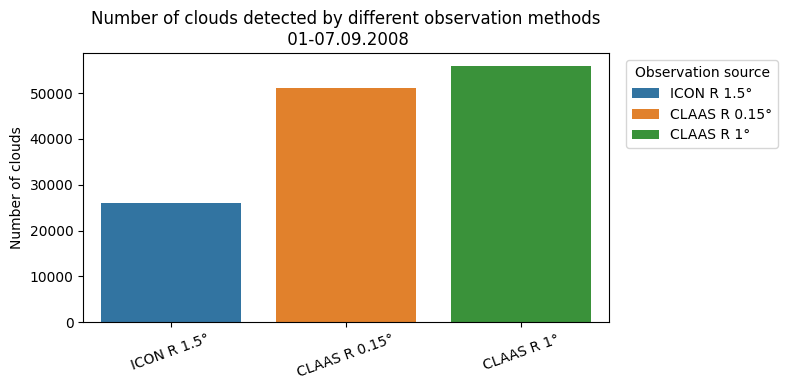

In [127]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# Count rows in each dataframe
counts = pd.DataFrame({
    "Observation method": [
        "ICON R 1.5°",
        "CLAAS R 0.15°",
        "CLAAS R 1°"
        
    ],
    "Num clouds (rows)": [
        len(clouds_model),
        len(clouds_high_res),
        len(clouds_low_res)
    ]
})

plt.figure(figsize=(8, 4))
ax = sns.barplot(
    data=counts,
    x="Observation method",
    y="Num clouds (rows)",
    hue="Observation method",      # makes a legend
    dodge=False
)

ax.set_xlabel("")
ax.set_ylabel("Number of clouds")
ax.tick_params(axis="x", rotation=20)
ax.legend(title="Observation source", bbox_to_anchor=(1.02, 1), loc="upper left")

# (optional) add value labels on bars
# for container in ax.containers:
#     ax.bar_label(container, fmt="%.0f", padding=3)
ax.set_title("Number of clouds detected by different observation methods\n 01-07.09.2008")
plt.tight_layout()
plt.show()


In [128]:
(clouds_model["avg_size[km]"]<0.01e7).value_counts(normalize=True)

avg_size[km]
True     0.948607
False    0.051393
Name: proportion, dtype: float64

In [129]:
import seaborn as sns

NameError: name 'clouds_model_offline' is not defined

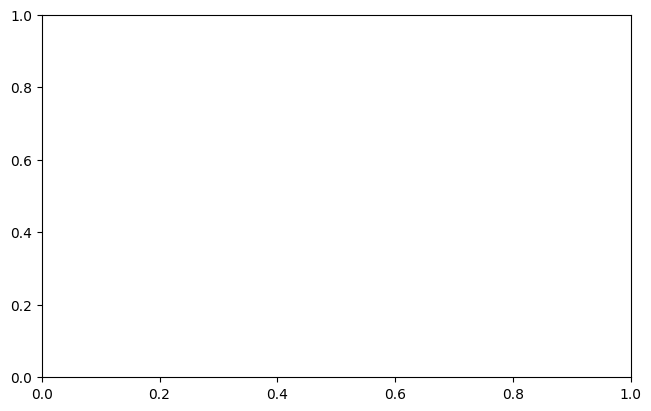

In [130]:
fig,ax = plt.subplots(1, 1, figsize=(6.4,  4), layout="constrained")
sns.histplot(clouds_model_offline[clouds_model_offline["avg_size[km]"]<1e5]["avg_size[km]"], log_scale=(False, True), bins=20,ax= ax,label="ICON R 1.5°" )
sns.histplot(clouds_high_res[clouds_high_res["avg_size[km]"]<1e5]["avg_size[km]"], log_scale=(False, True), bins=20,ax= ax,label="CLAAS R 0.05°")
ax.set_title('Cloud top area distribution \n for different observation methods \n 01-07.09.2008')
plt.legend()
ax.set_xlabel('Cloud top area [km^2]')

In [ ]:
(clouds_high_res["avg_size[km]"]<0.01e7).value_counts(normalize=True)

avg_size[km]
True     0.995968
False    0.004032
Name: proportion, dtype: float64

<Axes: xlabel='avg_size[km]', ylabel='Count'>

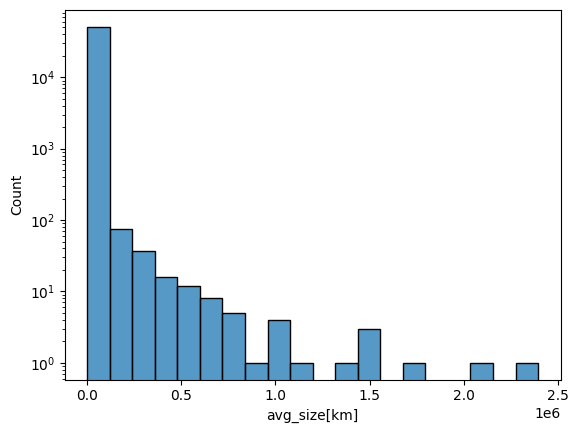

In [ ]:
sns.histplot(clouds_high_res["avg_size[km]"], log_scale=(False, True), bins=20)


(array([ 984., 2945., 4112., 4372., 2182., 1821., 1577., 1198., 1052.,
         821.,  680.,  549.,  446.,  377.,  375.,  325.,  262.,  235.,
         219.,  163.]),
 array([ 4727.57163698,  9490.19424635, 14252.81685573, 19015.4394651 ,
        23778.06207447, 28540.68468384, 33303.30729322, 38065.92990259,
        42828.55251196, 47591.17512133, 52353.7977307 , 57116.42034008,
        61879.04294945, 66641.66555882, 71404.28816819, 76166.91077756,
        80929.53338694, 85692.15599631, 90454.77860568, 95217.40121505,
        99980.02382443]),
 <BarContainer object of 20 artists>)

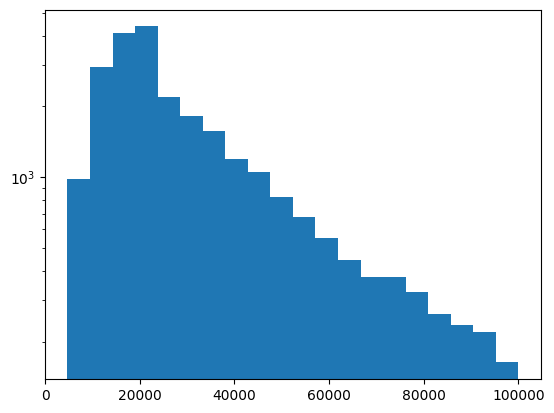

In [ ]:
# clouds_model_offline[clouds_model_offline["avg_size[km]"]<0.1e7]["avg_size[km]"].hist()
plt.hist(clouds_model_offline[clouds_model_offline["avg_size[km]"]<0.01e7]["avg_size[km]"], log=True, bins=20)

## Pixel area irregular grid

In [ ]:
np.arange(-36,-6+1,6)

array([-36, -30, -24, -18, -12,  -6])

In [ ]:
[f"{i} to {i+6}" for i in range(-36,0,6)]

['-36 to -30',
 '-30 to -24',
 '-24 to -18',
 '-18 to -12',
 '-12 to -6',
 '-6 to 0']

In [ ]:
def lat_to_pix_arr(lat_arr,lon_arr):
    """
    Convert latitude and longitude arrays to pixel indices based on the given resolution in degrees.
    
    Parameters:
    lat_arr (array-like): 2D Array of latitude values.
    lon_arr (array-like): 2D Array of longitude values.

    Returns:
    tuple: Two arrays containing the pixel indices for latitude and longitude.
    """
    res_lat = np.pad(abs(lat_arr[0,1:,0] - lat_arr[0,:-1,0]),(0,1), 'edge')  # degrees per pixel latitude direction
    res_lon = np.pad(abs(lon_arr[0,0,1:] - lon_arr[0,0,:-1]),(0,1), 'edge')   # degrees per pixel longitude direction
    return 110*110*np.outer(res_lat,res_lon)[np.newaxis,:,:]*np.cos(np.deg2rad(lat_arr)) 

test_lat_arr = np.tile(np.flip(np.linspace(-90,90,361)[:,np.newaxis],axis=0),(1,320))[np.newaxis,:,:]
test_lon_arr = np.tile(np.linspace(-120,120,320),(361,1))[np.newaxis,:,:]
result = lat_to_pix_arr(test_lat_arr,test_lon_arr)
print(test_lat_arr.shape,test_lon_arr.shape)

(1, 361, 320) (1, 361, 320)


In [ ]:
result.shape

(1, 361, 320)

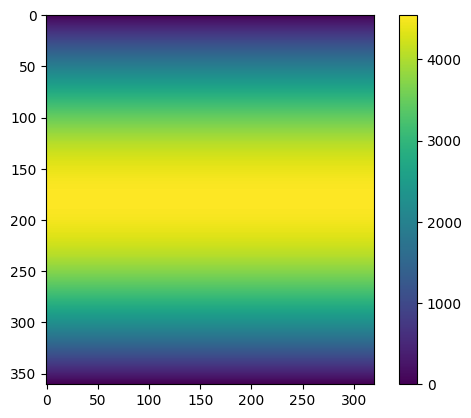

In [ ]:
plt.imshow(result[0])
plt.colorbar()

In [ ]:
 low_res_occ_rate

min_temp,-36,-30,-24,-18,-12,-6
Hemisphere,,,,,,
North,0.043093,0.042002,0.026807,0.021797,0.007609,0.000225
South,0.049425,0.030884,0.018008,0.014098,0.005281,0.000181
